In [18]:
!pip install torchvision


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [19]:
import torch
import os
from torch.utils.data import DataLoader,Dataset
from torchvision import transforms

In [20]:
# images load => transform => dataset of all imgs
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # list of paths for all images
        self.all_img_paths = [os.path.join(root_dir_path, img) for img in os.listdir(root_dir_path)]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [21]:
root_dir_path = "./img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178), # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # [-1, 1]
])

In [22]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

loaded 202599 images


In [23]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

# generator netwrk

In [24]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [25]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3): # 3 is for RGB
        super(Generator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256), # 100 => 256
            nn.ReLU(),

            nn.Linear(256, 512), 
            nn.ReLU(),

            nn.Linear(512, 1024), 
            nn.ReLU(),

            nn.Linear(1024, 64 * 64 * img_channels), 
            nn.Tanh() # [-1, 1]
        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64) 
        return img

        # fake img => 64 x 64 x 3 x batch_size

## discriminator

In [26]:
class Discriminator(nn.Module):
    def __init__(self, img_channels=3): # 3 is for RGB
        super(Discriminator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Flatten(), # 4D tensor => 1D
            
            nn.Linear(img_channels * 64 * 64, 1024),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 512), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1), 
            nn.Sigmoid() # probability of being real/fake 
        )

    def forward(self, img):
        return self.model(img)

In [27]:
GAN_loss = nn.BCELoss()

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))


In [28]:
import torch
# device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"device is {device}")

device is mps


In [29]:
generator = generator.to(device)
discriminator = discriminator.to(device)

## training GANs


In [30]:
def train(generator, discriminator, dataloader, epochs=10):

    for epoch in range(epochs):
        for i, imgs in enumerate(dataloader):
            real_imgs = imgs.to(device)
            batch_size = real_imgs.size(0)

            # creates real imgs labels & fake imgs labels
            real_labels = torch.ones(batch_size, 1).to(device) # [1, 1, 1....]
            fake_labels = torch.zeros(batch_size, 1).to(device) # [0, 0, 0....]

            # Train the Discriminator
            d_optimizer.zero_grad()

            fake_imgs = generator(torch.randn(batch_size, 100).to(device))

            real_loss = GAN_loss(discriminator(real_imgs), real_labels)
            fake_loss = GAN_loss(discriminator(fake_imgs.detach()), fake_labels)

            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()
            d_optimizer.step()

            # Train the Generator
            g_optimizer.zero_grad()

            g_loss = GAN_loss(discriminator(fake_imgs), real_labels)

            g_loss.backward()
            g_optimizer.step()

            if i % 50 == 0:
                print(f"for epoch: {epoch+1}/{epochs}... batch: {i+1}... G-loss:{g_loss}.... D-loss: {d_loss}")

        # save generated imgs for each epoch
        save_generated_images(generator, epoch, device) 

In [36]:
import matplotlib.pyplot as plt
import torchvision
import numpy as np
import torch
from PIL import Image

def save_generated_images(generator, epoch, device, num_imgs=8):
    z = torch.randn(num_imgs, 100).to(device)

    with torch.no_grad():
        generated_imgs = generator(z).cpu()

    grid = torchvision.utils.make_grid(
        generated_imgs, nrow=4, normalize=True
    )

    plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
    plt.title(f"Epoch {epoch + 1}")
    plt.axis("off")
    plt.show()

for epoch: 1/5... batch: 1... G-loss:0.7232100367546082.... D-loss: 0.6942130923271179
for epoch: 1/5... batch: 51... G-loss:1.0206823348999023.... D-loss: 0.3290292024612427
for epoch: 1/5... batch: 101... G-loss:0.8496264219284058.... D-loss: 0.3216956555843353
for epoch: 1/5... batch: 151... G-loss:1.83651864528656.... D-loss: 0.11740192770957947
for epoch: 1/5... batch: 201... G-loss:2.01462984085083.... D-loss: 0.08229435980319977
for epoch: 1/5... batch: 251... G-loss:4.1364850997924805.... D-loss: 0.035888031125068665
for epoch: 1/5... batch: 301... G-loss:3.3126869201660156.... D-loss: 0.01862165704369545
for epoch: 1/5... batch: 351... G-loss:3.653646469116211.... D-loss: 0.15034279227256775
for epoch: 1/5... batch: 401... G-loss:3.4029722213745117.... D-loss: 0.03836870193481445
for epoch: 1/5... batch: 451... G-loss:4.493472099304199.... D-loss: 0.01523318700492382
for epoch: 1/5... batch: 501... G-loss:3.576925754547119.... D-loss: 0.12280461192131042
for epoch: 1/5... batc

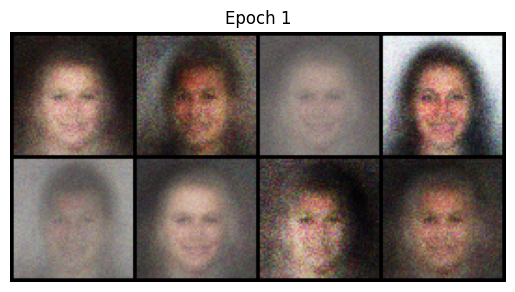

for epoch: 2/5... batch: 1... G-loss:3.0419251918792725.... D-loss: 0.3308197855949402
for epoch: 2/5... batch: 51... G-loss:2.745053291320801.... D-loss: 0.5075123906135559
for epoch: 2/5... batch: 101... G-loss:2.9007318019866943.... D-loss: 0.26538705825805664
for epoch: 2/5... batch: 151... G-loss:2.6750659942626953.... D-loss: 0.21603593230247498
for epoch: 2/5... batch: 201... G-loss:2.9285387992858887.... D-loss: 0.27895140647888184
for epoch: 2/5... batch: 251... G-loss:2.8389034271240234.... D-loss: 0.19230878353118896
for epoch: 2/5... batch: 301... G-loss:2.718244791030884.... D-loss: 0.5119374990463257
for epoch: 2/5... batch: 351... G-loss:2.8980560302734375.... D-loss: 0.2724674940109253
for epoch: 2/5... batch: 401... G-loss:2.6271471977233887.... D-loss: 0.29118403792381287
for epoch: 2/5... batch: 451... G-loss:3.2201967239379883.... D-loss: 0.24756062030792236
for epoch: 2/5... batch: 501... G-loss:2.761911392211914.... D-loss: 0.48355165123939514
for epoch: 2/5... ba

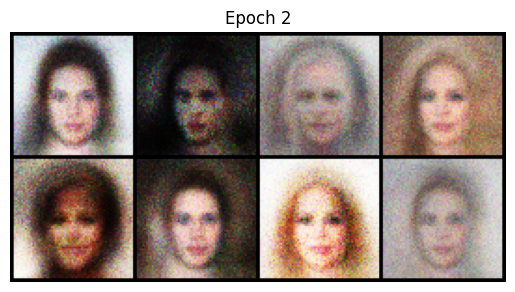

for epoch: 3/5... batch: 1... G-loss:2.574974775314331.... D-loss: 0.3823583722114563
for epoch: 3/5... batch: 51... G-loss:2.7510828971862793.... D-loss: 0.37402841448783875
for epoch: 3/5... batch: 101... G-loss:2.086643934249878.... D-loss: 0.40711522102355957
for epoch: 3/5... batch: 151... G-loss:2.633462905883789.... D-loss: 0.39354389905929565
for epoch: 3/5... batch: 201... G-loss:2.1470823287963867.... D-loss: 0.46691063046455383
for epoch: 3/5... batch: 251... G-loss:3.2778165340423584.... D-loss: 0.32448452711105347
for epoch: 3/5... batch: 301... G-loss:2.0183193683624268.... D-loss: 0.43207722902297974
for epoch: 3/5... batch: 351... G-loss:2.3787198066711426.... D-loss: 0.4368968904018402
for epoch: 3/5... batch: 401... G-loss:2.149135112762451.... D-loss: 0.4695245921611786
for epoch: 3/5... batch: 451... G-loss:2.3230888843536377.... D-loss: 0.5335679650306702
for epoch: 3/5... batch: 501... G-loss:1.748626470565796.... D-loss: 0.4050038456916809
for epoch: 3/5... batch

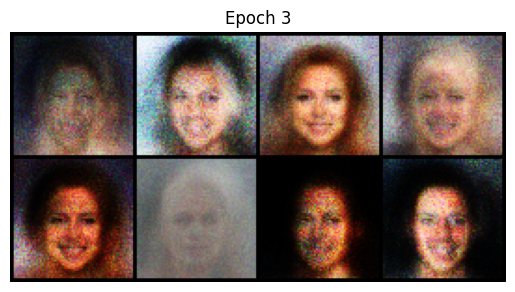

for epoch: 4/5... batch: 1... G-loss:2.0213422775268555.... D-loss: 0.43483662605285645
for epoch: 4/5... batch: 51... G-loss:2.0841689109802246.... D-loss: 0.40243786573410034
for epoch: 4/5... batch: 101... G-loss:1.7846832275390625.... D-loss: 0.49048128724098206
for epoch: 4/5... batch: 151... G-loss:1.6194686889648438.... D-loss: 0.4347989559173584
for epoch: 4/5... batch: 201... G-loss:2.4828875064849854.... D-loss: 0.48209282755851746
for epoch: 4/5... batch: 251... G-loss:1.7429125308990479.... D-loss: 0.47477859258651733
for epoch: 4/5... batch: 301... G-loss:2.068342685699463.... D-loss: 0.5358662009239197
for epoch: 4/5... batch: 351... G-loss:1.6104570627212524.... D-loss: 0.5291011333465576
for epoch: 4/5... batch: 401... G-loss:2.2968902587890625.... D-loss: 0.4474520683288574
for epoch: 4/5... batch: 451... G-loss:1.7167792320251465.... D-loss: 0.4311935305595398
for epoch: 4/5... batch: 501... G-loss:1.5423004627227783.... D-loss: 0.44618165493011475
for epoch: 4/5... b

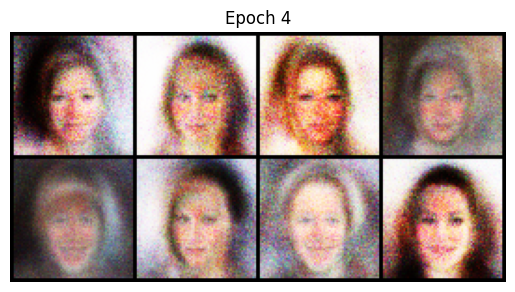

for epoch: 5/5... batch: 1... G-loss:1.728698968887329.... D-loss: 0.5540593862533569
for epoch: 5/5... batch: 51... G-loss:1.7788715362548828.... D-loss: 0.46026790142059326
for epoch: 5/5... batch: 101... G-loss:1.6810134649276733.... D-loss: 0.4289252758026123
for epoch: 5/5... batch: 151... G-loss:1.5812709331512451.... D-loss: 0.5121948719024658
for epoch: 5/5... batch: 201... G-loss:1.7643150091171265.... D-loss: 0.5131774544715881
for epoch: 5/5... batch: 251... G-loss:1.519352912902832.... D-loss: 0.5082971453666687
for epoch: 5/5... batch: 301... G-loss:1.5993237495422363.... D-loss: 0.5052276253700256
for epoch: 5/5... batch: 351... G-loss:1.8073780536651611.... D-loss: 0.4968610405921936
for epoch: 5/5... batch: 401... G-loss:1.393021821975708.... D-loss: 0.4927498400211334
for epoch: 5/5... batch: 451... G-loss:1.4366705417633057.... D-loss: 0.5127623081207275
for epoch: 5/5... batch: 501... G-loss:1.809796929359436.... D-loss: 0.4755275249481201
for epoch: 5/5... batch: 55

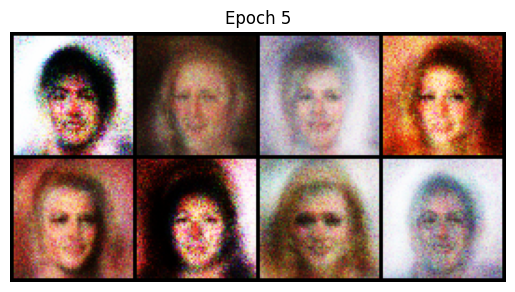

In [37]:
train(generator, discriminator, dataloader, epochs=5)